# 04 · Validación y comparación de modelos

**Propósito.** Validar el precio esperado que produce la etapa 6 del pipeline (`src/analisis.py`) y decidir, con
evidencia, qué modelo y qué zona de referencia usar. Responde a cuatro pedidos de la devolución de la PreEntrega 2 y
de la consigna de la PreEntrega 3:

| Pedido | Sección |
|---|---|
| Controlar el leakage indirecto (atípicos y elección de sub-zonas con todos los avisos, particiones no agrupadas) | 2 |
| Revisar la estabilidad de las sub-zonas | 3 |
| Comparar con una referencia razonable, fuera de muestra, y justificar qué aporta cada técnica frente a una más simple | 4 |
| Reportar incertidumbre, no solo un número | 5 |
| Primas por característica con su incertidumbre, y si cambian según el segmento (pregunta G2) | 6 y 7 |

**Cómo se valida.** Todos los modelos usan las mismas cinco vueltas de validación cruzada, armadas por unidad (misma
dirección y superficie), y en cada vuelta las decisiones que dependen del precio (qué barrios usan sub-zona, qué
avisos son atípicos) se toman solo con los avisos de entrenamiento (`modelo.vueltas_sin_fuga`). El error es el error
porcentual absoluto del precio por m² de cada aviso, fuera de muestra.

## 1. Configuración e ingesta

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import analisis, modelo, validacion
from src.configuracion import cargar_config
from src.eda import AZUL, AZUL_OSCURO, GRIS, ROJO, nombre_barrio

CFG = cargar_config()
PARAMS = {**CFG["analisis"], "b_bootstrap": 300}
limpio = pd.read_csv(RAIZ / CFG["rutas"]["limpio"], sep="\t", low_memory=False)
con_fuentes = analisis.unir_fuentes_externas(limpio, CFG["rutas"])
# Como en la etapa 6: los avisos con geocodificación dudosa (a más de 1 km del barrio buscado) se tratan como
# sin coordenadas, y las sub-zonas se recalculan sin ellos
df = analisis.tratar_geo_dudoso(con_fuentes, CFG["enriquecimiento"])
oficial = pd.read_csv(RAIZ / CFG["rutas"]["precio_esperado"], sep="\t")
print(f"Avisos con geocodificación dudosa: {int(con_fuentes['geo_dudoso'].fillna(0).sum())}")
y = np.log(df["precio_m2_usd"])
unidad = modelo.grupo_de_unidad(df)
print(f"Avisos: {len(df):,} | unidades: {unidad.nunique():,}")
PARAMS

/Users/gonzalobuhler/Documents/Facultad (ITBA)/2026 - 2C/Descriptiva/tp1-fondo-inmobiliario/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Definiendo sub-zonas por clustering...


  Sub-zonas creadas: 196 en total.
Avisos con geocodificación dudosa: 245
Avisos: 27,578 | unidades: 24,552


{'k_folds': 5,
 'semilla': 42,
 'minimo_grupo': 10,
 'iqr_k': 1.5,
 'umbral': -0.25,
 'minimo_avisos_barrio': 50,
 'modelo_oficial': 'lineal_ampliado',
 'nivel_intervalo': 0.8,
 'ari_minimo_subzona': 0.7,
 'repeticiones_estabilidad': 100,
 'b_bootstrap': 300}

## 2. Leakage indirecto: ¿cuánto cambia el modelo al tomar todas las decisiones dentro de cada vuelta?

**Pregunta:** en la PreEntrega 2, la marca de atípicos y la elección de los barrios con sub-zona se calcularon con
todos los avisos antes de la validación cruzada, y la comparación de H2 usaba particiones que no agrupaban por unidad.
¿Inflaba eso el desempeño del modelo?

Se comparan cuatro versiones del mismo modelo lineal, cambiando una cosa por vez:

1. **PreEntrega 2:** decisiones con todos los avisos; atípicos con IQR sobre el precio por m².
2. **Sin fuga, mismo criterio de atípicos:** decisiones dentro de cada vuelta, partes por unidad.
3. **Sin fuga, atípicos sobre el logaritmo:** además, los atípicos se miden sobre el log del precio por m², dentro de
   la zona (es la versión oficial de la etapa 6).

In [2]:
X = modelo.matriz_caracteristicas(df)
folds = modelo.folds_agrupados(unidad, PARAMS["k_folds"], PARAMS["semilla"])

# 1. Método de la PreEntrega 2
tabla_pe2 = modelo.barrios_donde_conviene_subzona(df, PARAMS["k_folds"], PARAMS["minimo_grupo"], PARAMS["semilla"])
zona_pe2 = modelo.zona_de_referencia(df, tabla_pe2.index[tabla_pe2["conviene_subzona"]], PARAMS["minimo_grupo"])
log_pe2, _ = modelo.precio_esperado_fuera_de_muestra(y, modelo.matriz_diseno(X, zona_pe2), zona_pe2, folds,
                                                     ~df["outlier_precio_m2"])
# 2 y 3. Sin fuga
sin_fuga_lineal = modelo.precio_esperado_sin_fuga(df, y, X, atipicos_en_log=False)
sin_fuga_log = modelo.precio_esperado_sin_fuga(df, y, X, atipicos_en_log=True)

versiones = {
    "1. PreEntrega 2": log_pe2,
    "2. Sin fuga, atípicos sobre el precio": sin_fuga_lineal["log_esperado"],
    "3. Sin fuga, atípicos sobre el log (oficial)": sin_fuga_log["log_esperado"],
}
fuga = pd.DataFrame({
    nombre: {
        "error_mediano_%": 100 * (np.exp(y - pred) - 1).abs().median(),
        "error_p75_%": 100 * (np.exp(y - pred) - 1).abs().quantile(0.75),
        "marcados (brecha < −25%)": int(((np.exp(y - pred) - 1) < PARAMS["umbral"]).sum()),
    } for nombre, pred in versiones.items()
}).T.round(2)
tabla_unidad = modelo.barrios_donde_conviene_subzona(df, PARAMS["k_folds"], PARAMS["minimo_grupo"], PARAMS["semilla"],
                                                     por_unidad=True)
print(f"Barrios donde conviene la sub-zona: {tabla_pe2['conviene_subzona'].sum()} con partes al azar, "
      f"{tabla_unidad['conviene_subzona'].sum()} con partes por unidad (de {len(tabla_unidad)})")
fuga

Barrios donde conviene la sub-zona: 31 con partes al azar, 34 con partes por unidad (de 46)


,error_mediano_%,error_p75_%,marcados (brecha < −25%)
1. PreEntrega 2,12.64,22.15,1668.0
"2. Sin fuga, atípicos sobre el precio",12.67,22.36,1685.0
"3. Sin fuga, atípicos sobre el log (oficial)",12.69,22.19,1875.0


In [3]:
marca = {n: (np.exp(y - p) - 1) < PARAMS["umbral"] for n, p in versiones.items()}
nombres = list(versiones)
print("Coincidencia de los avisos marcados (Jaccard):")
for a, b in [(0, 1), (1, 2), (0, 2)]:
    print(f"  {nombres[a][:2]} vs {nombres[b][:2]}: {validacion.jaccard(marca[nombres[a]], marca[nombres[b]]):.2f}")

Coincidencia de los avisos marcados (Jaccard):
  1. vs 2.: 0.87
  2. vs 3.: 0.87
  1. vs 3.: 0.81


> **Interpretación:** _(a completar)_

## 3. Estabilidad de las sub-zonas

**Pregunta:** las sub-zonas salen de un k-means sobre latitud y longitud dentro de cada barrio. ¿Son una partición
estable del barrio o cambian con la muestra?

**Cómo se mide.** Para cada barrio se repite el k-means 50 veces, con la misma cantidad de sub-zonas, sobre
submuestras del 80% de los avisos y otra semilla; se asignan todos los avisos y se compara con las sub-zonas
originales con el **índice de Rand ajustado** (ARI: 1 = misma partición, 0 = coincidencia al azar). Se toma como
estable un ARI mediano de al menos 0,7. Solo usa coordenadas, no precios: no tiene riesgo de fuga.

Se mide dos veces: con las sub-zonas originales de la etapa 4, que incluyen los avisos con geocodificación dudosa, y
con las sub-zonas recalculadas sin ellos, que son las que usa la etapa 6.

In [4]:
estab_antes = validacion.estabilidad_subzonas(con_fuentes, repeticiones=PARAMS["repeticiones_estabilidad"])
estab = validacion.estabilidad_subzonas(df, repeticiones=PARAMS["repeticiones_estabilidad"])
comparacion_estab = pd.DataFrame({"ari_con_geo_dudoso": estab_antes["ari_mediano"], "ari_sin_geo_dudoso": estab["ari_mediano"]})
print(f"Barrios inestables (ARI < 0,7): con geo dudoso {(estab_antes['ari_mediano'] < 0.7).sum()} | "
      f"sin geo dudoso {(estab['ari_mediano'] < 0.7).sum()}")
comparacion_estab.sort_values("ari_con_geo_dudoso").round(2).head(8)

Barrios inestables (ARI < 0,7): con geo dudoso 5 | sin geo dudoso 0


,ari_con_geo_dudoso,ari_sin_geo_dudoso
barrio,,
velez-sarsfield,-0.00,0.81
parque-patricios,0.46,0.94
villa-santa-rita,0.47,0.86
villa-luro,0.53,0.99
san-nicolas,0.66,0.94
coghlan,0.74,0.72
san-telmo,0.75,0.89
recoleta,0.75,0.98


In [5]:
usa_sub = oficial.assign(usa=oficial["zona"] != oficial["barrio"]).groupby("barrio")["usa"].mean()
estab["avisos_con_subzona_%"] = (100 * usa_sub.reindex(estab.index)).round(0)
estab["estable"] = estab["ari_mediano"] >= 0.7
print(f"Barrios evaluados: {len(estab)} | estables: {estab['estable'].sum()} | inestables: {(~estab['estable']).sum()}")
estab.round(2).head(10)

Barrios evaluados: 41 | estables: 41 | inestables: 0


,avisos,subzonas,ari_mediano,ari_p10,avisos_con_subzona_%,estable
barrio,,,,,,
coghlan,147,4,0.72,0.57,16.0,True
villa-general-mitre,79,2,0.76,0.41,0.0,True
villa-pueyrredon,200,5,0.77,0.59,54.0,True
parque-chacabuco,269,5,0.78,0.64,0.0,True
barrio-norte,619,5,0.78,0.58,66.0,True
velez-sarsfield,62,2,0.81,0.69,49.0,True
boedo,375,5,0.84,0.44,89.0,True
chacarita,190,5,0.84,0.61,85.0,True
la-boca,172,5,0.86,0.80,57.0,True


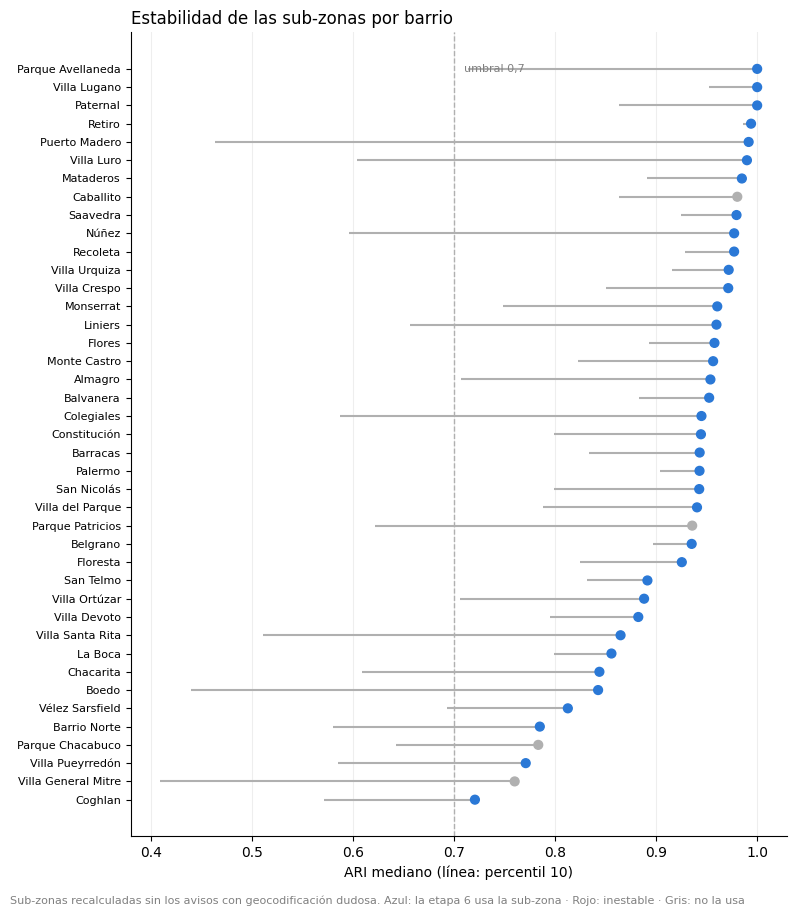

In [6]:
fig, ax = plt.subplots(figsize=(8, 9))
orden = estab.sort_values("ari_mediano")
colores = [ROJO if not e else (AZUL if u > 0 else GRIS)
           for e, u in zip(orden["estable"], orden["avisos_con_subzona_%"].fillna(0))]
ax.hlines(range(len(orden)), orden["ari_p10"], orden["ari_mediano"], color=GRIS, lw=1.5)
ax.scatter(orden["ari_mediano"], range(len(orden)), color=colores, s=40, zorder=3)
ax.axvline(0.7, color=GRIS, ls="--", lw=1)
ax.set_yticks(range(len(orden)), [nombre_barrio(b) for b in orden.index], fontsize=8)
ax.set_xlabel("ARI mediano (línea: percentil 10)")
ax.set_title("Estabilidad de las sub-zonas por barrio", loc="left")
ax.text(0.71, len(orden) - 1, "umbral 0,7", color="gray", fontsize=8, va="center")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.01, "Sub-zonas recalculadas sin los avisos con geocodificación dudosa. Azul: la etapa 6 usa la sub-zona · Rojo: inestable · Gris: no la usa",
            fontsize=8, color="gray")
plt.tight_layout()
plt.show()

In [7]:
estab = estab.copy()
inestables_en_uso = estab[~estab["estable"]]
print("Barrios con sub-zonas inestables (la etapa 6 los compara contra el barrio completo):")
inestables_en_uso.round(2)

Barrios con sub-zonas inestables (la etapa 6 los compara contra el barrio completo):


,avisos,subzonas,ari_mediano,ari_p10,avisos_con_subzona_%,estable
barrio,,,,,,


In [8]:
# Sensibilidad: ¿qué pasa si los barrios inestables, o los que quedan cerca del umbral (ARI < 0,8),
# se comparan contra el barrio completo?
inestables = list(estab.index[~estab["estable"]])
al_limite = list(estab.index[estab["ari_mediano"] < 0.8])
print("Inestables:", inestables or "ninguno", "| cerca del umbral:", al_limite)
escenarios = [("Oficial", sin_fuga_log)]
if inestables:
    escenarios.append(("Sin sub-zona en barrios inestables",
                       modelo.precio_esperado_sin_fuga(df, y, X, barrios_excluidos=inestables)))
escenarios.append(("Sin sub-zona en barrios con ARI < 0,8",
                   modelo.precio_esperado_sin_fuga(df, y, X, barrios_excluidos=al_limite)))
for nombre, s in escenarios:
    b = np.exp(y - s["log_esperado"]) - 1
    print(f"{nombre}: error mediano {100 * b.abs().median():.2f}% | marcados {(b < PARAMS['umbral']).sum():,}")

Inestables: ninguno | cerca del umbral: ['coghlan', 'villa-general-mitre', 'villa-pueyrredon', 'parque-chacabuco', 'barrio-norte']


Oficial: error mediano 12.69% | marcados 1,875
Sin sub-zona en barrios con ARI < 0,8: error mediano 12.68% | marcados 1,874


> **Interpretación:** _(a completar)_

## 4. Comparación de modelos

**Pregunta:** ¿qué aporta cada técnica frente a una más simple?

| Modelo | Qué es | Qué aporta / qué cuesta |
|---|---|---|
| Mediana de la zona | El precio por m² típico de la zona | La referencia más simple: no usa las características del departamento |
| Lineal (PreEntrega 2) | Regresión del log del precio por m² sobre características + zona | Primas interpretables (% por característica) |
| Lineal ampliado | Más las marcas del título (estado, tipología) y las expensas relativas a la zona | Suma información que la ficha no tiene, sigue siendo interpretable |
| Ridge | El ampliado con regularización L2 | Controla el sobreajuste si hay muchas zonas con pocos avisos |
| Gradient boosting | Árboles con las mismas variables más latitud, longitud y barrio | Capta interacciones y la micro-ubicación; no da primas, es una caja más negra |

Todos con las mismas vueltas y las mismas decisiones sin fuga.

In [9]:
inestables = list(estab.index[~estab["estable"]])
pred, vuelta = validacion.comparar_modelos(df, y, PARAMS["k_folds"], PARAMS["semilla"], PARAMS["minimo_grupo"],
                                           PARAMS["iqr_k"], barrios_excluidos=inestables)
tabla_modelos = validacion.metricas(y, pred, PARAMS["umbral"]).round(2)
tabla_modelos

,error_mediano_%,error_p75_%,dentro_de_10%_%,marcados
mediana_zona,17.51,29.91,29.75,3409.0
lineal,12.69,22.19,40.58,1875.0
lineal_ampliado,12.49,21.87,41.18,1800.0
ridge,12.50,21.86,41.22,1798.0
gbm,11.24,19.92,45.24,1456.0


In [10]:
# IC 95% de la diferencia de error mediano contra el lineal, remuestreando unidades
dif = pd.DataFrame({m: validacion.bootstrap_diferencia_error(y, pred[m], pred["lineal"], unidad, b=PARAMS["b_bootstrap"])
                    for m in ["mediana_zona", "lineal_ampliado", "ridge", "gbm"]},
                   index=["diferencia_pp", "ic_inf_pp", "ic_sup_pp"]).T.round(2)
dif

,diferencia_pp,ic_inf_pp,ic_sup_pp
mediana_zona,4.82,4.57,5.08
lineal_ampliado,-0.21,-0.29,-0.09
ridge,-0.20,-0.28,-0.10
gbm,-1.45,-1.61,-1.29


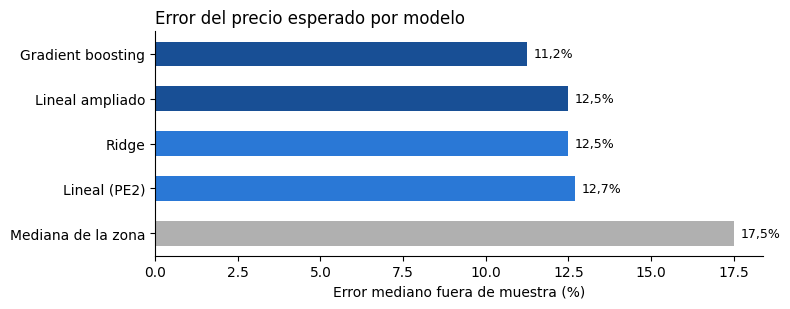

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
etiquetas = {"mediana_zona": "Mediana de la zona", "lineal": "Lineal (PE2)", "lineal_ampliado": "Lineal ampliado",
             "ridge": "Ridge", "gbm": "Gradient boosting"}
orden = tabla_modelos["error_mediano_%"].sort_values(ascending=False)
colores = [GRIS if m == "mediana_zona" else (AZUL_OSCURO if m in ("lineal_ampliado", "gbm") else AZUL) for m in orden.index]
ax.barh(range(len(orden)), orden.values, color=colores, height=0.55)
for i, v in enumerate(orden.values):
    ax.text(v + 0.2, i, f"{v:.1f}%".replace(".", ","), va="center", fontsize=9)
ax.set_yticks(range(len(orden)), [etiquetas[m] for m in orden.index])
ax.set_xlabel("Error mediano fuera de muestra (%)")
ax.set_title("Error del precio esperado por modelo", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**¿Cambia el ranking según el modelo?** Si dos modelos con error parecido marcan avisos distintos, la marca depende
de la elección del modelo y no solo del precio del aviso. Se mide la coincidencia de los marcados (Jaccard) y cuántos
marca cada par en común.

In [12]:
brechas = np.exp(y.values[:, None] - pred.values) - 1
marcas = pd.DataFrame(brechas < PARAMS["umbral"], index=df.index, columns=pred.columns)
modelos = ["lineal", "lineal_ampliado", "ridge", "gbm"]
coincidencia = pd.DataFrame([[validacion.jaccard(marcas[a], marcas[b]) for b in modelos] for a in modelos],
                            index=modelos, columns=modelos).round(2)
coincidencia

,lineal,lineal_ampliado,ridge,gbm
lineal,1.00,0.84,0.84,0.50
lineal_ampliado,0.84,1.00,0.98,0.52
ridge,0.84,0.98,1.00,0.52
gbm,0.50,0.52,0.52,1.00


In [13]:
consenso = marcas["lineal_ampliado"] & marcas["gbm"]
print(f"Marcados por el lineal ampliado: {marcas['lineal_ampliado'].sum():,} | por gradient boosting: {marcas['gbm'].sum():,} "
      f"| por los dos: {consenso.sum():,}")
# ¿Dónde se separan? Error de cada modelo por grupo de barrios según su precio
nivel = pd.qcut(df.groupby("barrio")["precio_m2_usd"].transform("median"), 3, labels=["barrios baratos", "medios", "caros"])
err = (np.exp(y.values[:, None] - pred.values) - 1)
pd.DataFrame(np.abs(err), columns=pred.columns).groupby(nivel.values, observed=True).median().mul(100).round(1)

Marcados por el lineal ampliado: 1,800 | por gradient boosting: 1,456 | por los dos: 1,112


,mediana_zona,lineal,lineal_ampliado,ridge,gbm
barrios baratos,17.6,12.7,12.5,12.6,11.3
medios,17.0,12.7,12.6,12.6,11.1
caros,17.8,12.7,12.4,12.4,11.2


> **Interpretación:** _(a completar)_

## 5. Incertidumbre: intervalo de predicción por aviso

**Pregunta:** el error mediano dice cuánto se equivoca el modelo en el aviso típico. ¿Cuánto puede equivocarse para
*un* aviso, en *su* barrio?

**Cómo se calcula (conformal cruzado).** Para los avisos de cada vuelta, el intervalo sale de los cuantiles de los
residuos fuera de muestra de las **otras** vueltas, dentro de su barrio (si tiene al menos 50 avisos; si no, de toda
la ciudad). No supone normalidad. **Cómo se valida:** la cobertura, es decir, qué proporción de avisos cae realmente
dentro de su intervalo, tiene que acercarse al nivel nominal (80% o 90%), en total y en cada barrio.

In [14]:
cobertura = []
intervalos = {}
for m in ["lineal_ampliado", "gbm"]:
    residuo = y - pred[m]
    for nivel_ic in [0.80, 0.90]:
        inf, sup = validacion.intervalos_conformes(residuo, df["barrio"], vuelta, nivel_ic)
        dentro = (residuo >= inf) & (residuo <= sup)
        por_barrio = dentro.groupby(df["barrio"]).mean()
        intervalos[(m, nivel_ic)] = (inf, sup, dentro)
        cobertura.append({"modelo": m, "nivel_%": int(100 * nivel_ic), "cobertura_%": 100 * dentro.mean(),
                          "cobertura_barrio_p10_%": 100 * por_barrio.quantile(0.1),
                          "cobertura_barrio_min_%": 100 * por_barrio.min(),
                          "ancho_mediano_%": 100 * (np.exp(sup - inf) - 1).median(),
                          "debajo_del_intervalo": int((residuo < inf).sum())})
pd.DataFrame(cobertura).round(1)

,modelo,nivel_%,cobertura_%,cobertura_barrio_p10_%,cobertura_barrio_min_%,ancho_mediano_%,debajo_del_intervalo
0,lineal_ampliado,80,79.5,74.5,43.9,65.2,2825
1,lineal_ampliado,90,89.5,86.3,53.7,93.7,1437
2,gbm,80,79.7,75.4,51.2,55.9,2808
3,gbm,90,89.5,84.9,65.9,81.8,1439


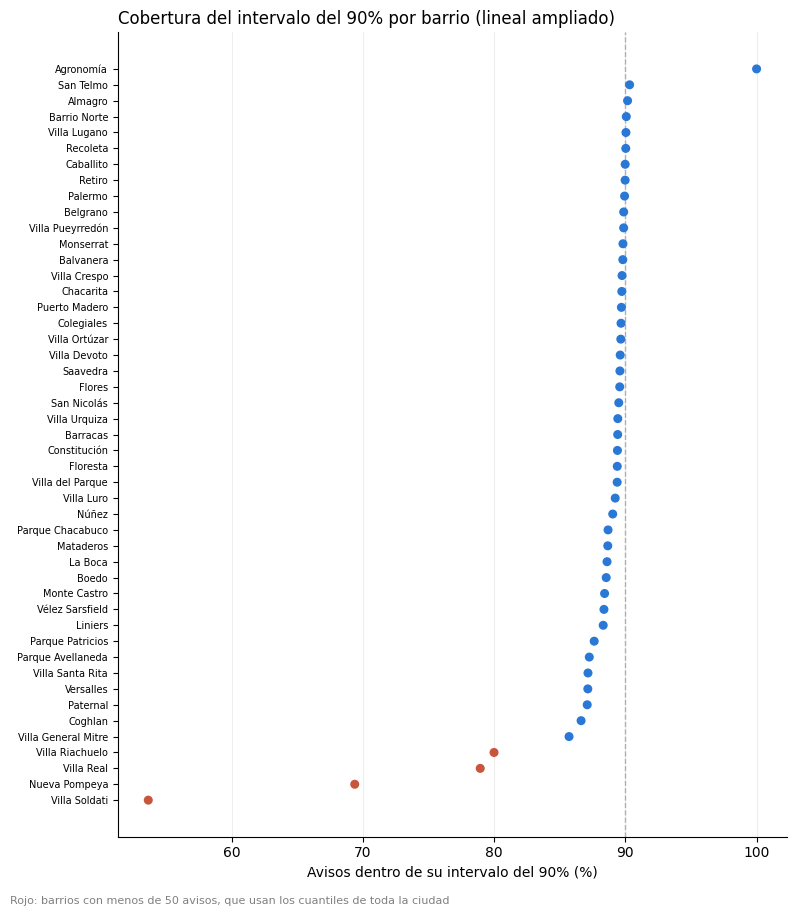

In [15]:
inf, sup, dentro = intervalos[("lineal_ampliado", 0.90)]
cob = dentro.groupby(df["barrio"]).agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 9))
colores = [ROJO if n < 50 else AZUL for n in cob["size"]]
ax.scatter(100 * cob["mean"], range(len(cob)), color=colores, s=30, zorder=3)
ax.axvline(90, color=GRIS, ls="--", lw=1)
ax.set_yticks(range(len(cob)), [nombre_barrio(b) for b in cob.index], fontsize=7)
ax.set_xlabel("Avisos dentro de su intervalo del 90% (%)")
ax.set_title("Cobertura del intervalo del 90% por barrio (lineal ampliado)", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.01, "Rojo: barrios con menos de 50 avisos, que usan los cuantiles de toda la ciudad", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

In [16]:
# Lo que significa para el ranking: un aviso por debajo de su intervalo del 90% pide menos que el 95% de los avisos
# comparables de su barrio, según el error del modelo ahí. ¿Coincide con la marca por barrio de la etapa 6?
residuo = y - pred["lineal_ampliado"]
debajo = residuo < inf
print(f"Debajo del intervalo del 90%: {debajo.sum():,} avisos | marca por barrio oficial: {oficial['marcado_barrio'].sum():,} "
      f"| coincidencia (Jaccard): {validacion.jaccard(debajo, oficial['marcado_barrio']):.2f}")

Debajo del intervalo del 90%: 1,437 avisos | marca por barrio oficial: 1,546 | coincidencia (Jaccard): 0.79


> **Interpretación:** _(a completar)_

## 6. Primas por característica con su incertidumbre

**Pregunta:** ¿cuánto paga el mercado por cada característica, dentro de la misma zona, y con qué precisión lo sabemos?

El modelo lineal ampliado se ajusta con todos los avisos (sin atípicos), con la zona de referencia de la etapa 6. El
intervalo de confianza del 95% sale de remuestrear **unidades** (no avisos), porque los avisos de una misma unidad no
son independientes. Las primas son asociaciones dentro de la zona, no efectos causales.

In [17]:
from src.limpieza import outliers_iqr_por_grupo

zona = oficial["zona"]
Xa = validacion.caracteristicas_ampliadas(df)
log_exp = np.log(df["expensas_usd"] / df["m2_final"])
Xa = Xa.assign(expensas_rel_zona=(log_exp - log_exp.groupby(zona).transform("median")).fillna(0),
               expensas_sin_dato=log_exp.isna().astype(float))
A = modelo.matriz_diseno(Xa, zona)
usar = ~outliers_iqr_por_grupo(y, zona, k=PARAMS["iqr_k"], minimo_grupo=PARAMS["minimo_grupo"])
caracteristicas = [c for c in Xa.columns if c not in ("log_m2",)]
primas = validacion.bootstrap_primas(y, A, usar, unidad, caracteristicas, b=PARAMS["b_bootstrap"]).round(1)
primas["significativa"] = (primas["ic_inf_%"] > 0) | (primas["ic_sup_%"] < 0)
primas.sort_values("prima_%")

,prima_%,ic_inf_%,ic_sup_%,significativa
titulo_a_reciclar,-18.0,-21.2,-15.4,True
titulo_a_refaccionar,-15.9,-18.6,-12.9,True
titulo_casa,-7.4,-18.9,5.8,False
apto_profesional,-3.0,-3.6,-2.6,True
apto_credito,-1.4,-1.9,-0.9,True
ascensor,-0.9,-1.6,-0.4,True
contrafrente,-0.5,-1.0,0.1,False
seguridad,0.6,-0.1,1.2,False
piso,0.7,0.6,0.8,True
antiguedad_51_70,0.8,-0.9,2.3,False


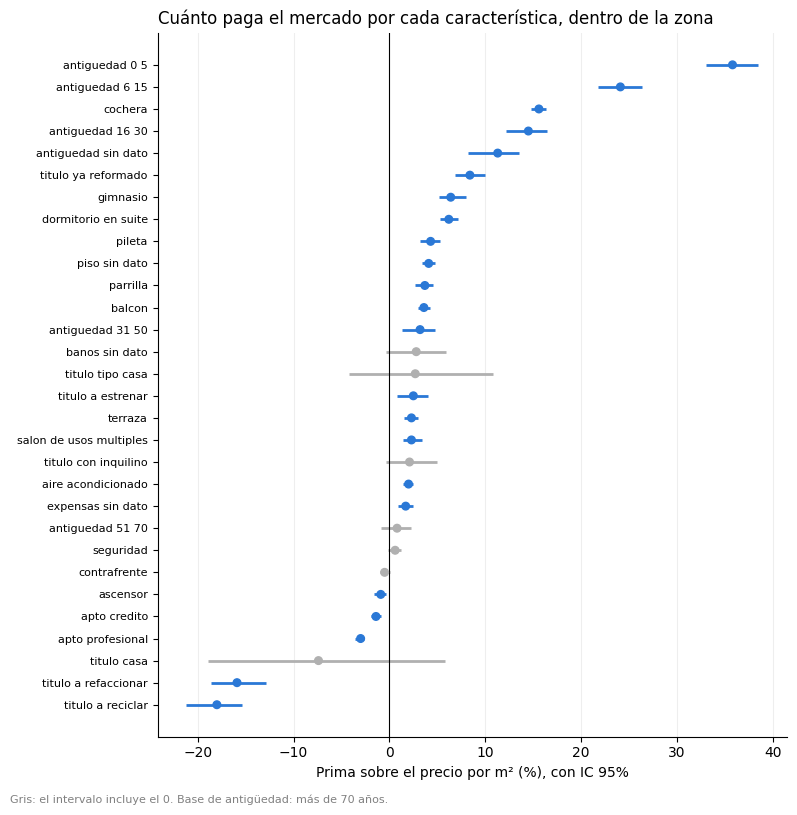

In [18]:
mostrar = primas.drop(["piso", "ambientes", "banos", "expensas_rel_zona"]).sort_values("prima_%")
fig, ax = plt.subplots(figsize=(8, 8))
color = [AZUL if s else GRIS for s in mostrar["significativa"]]
ax.hlines(range(len(mostrar)), mostrar["ic_inf_%"], mostrar["ic_sup_%"], color=color, lw=2)
ax.scatter(mostrar["prima_%"], range(len(mostrar)), color=color, s=30, zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(mostrar)), [c.replace("_", " ") for c in mostrar.index], fontsize=8)
ax.set_xlabel("Prima sobre el precio por m² (%), con IC 95%")
ax.set_title("Cuánto paga el mercado por cada característica, dentro de la zona", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.01, "Gris: el intervalo incluye el 0. Base de antigüedad: más de 70 años.", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

In [19]:
coef = modelo.ajustar(y, A, usar)
print(f"Superficie: +10% de m² se asocia a {modelo.prima_porcentual(coef['log_m2'] * np.log(1.1)):.1f}% de precio por m²")
print(f"Expensas: un edificio con expensas por m² 10% más caras que la mediana de su zona se publica "
      f"{modelo.prima_porcentual(coef['expensas_rel_zona'] * np.log(1.1)):+.1f}% por m²")
for c in ["ambientes", "banos", "piso"]:
    print(f"{c}: {primas.loc[c, 'prima_%']:+.1f}% por unidad adicional (IC {primas.loc[c, 'ic_inf_%']:+.1f} a {primas.loc[c, 'ic_sup_%']:+.1f})")

Superficie: +10% de m² se asocia a -1.6% de precio por m²
Expensas: un edificio con expensas por m² 10% más caras que la mediana de su zona se publica +0.4% por m²
ambientes: +2.2% por unidad adicional (IC +1.6 a +2.6)
banos: +4.6% por unidad adicional (IC +3.9 a +5.1)
piso: +0.7% por unidad adicional (IC +0.6 a +0.8)


> **Interpretación:** _(a completar)_

## 7. ¿Las primas cambian según el segmento? (pregunta G2)

**Pregunta:** un solo coeficiente por característica para toda la ciudad, ¿alcanza? Se separan los barrios en tres
grupos según su precio mediano por m² (baratos, medios, caros) y se estima el mismo modelo en cada grupo. Si los
intervalos de una característica no se superponen entre grupos, su prima depende del segmento.

In [20]:
segmento = pd.qcut(df.groupby("barrio")["precio_m2_usd"].transform("median"), 3, labels=["baratos", "medios", "caros"])
clave = ["antiguedad_0_5", "antiguedad_6_15", "cochera", "pileta", "seguridad", "balcon", "contrafrente",
         "titulo_a_refaccionar", "titulo_a_reciclar"]
por_segmento = {}
for seg in ["baratos", "medios", "caros"]:
    en = (segmento == seg).values
    A_seg = modelo.matriz_diseno(Xa[en], zona[en])
    por_segmento[seg] = validacion.bootstrap_primas(y[en], A_seg, usar[en], unidad[en], clave, b=150)
g2 = pd.concat(por_segmento, names=["segmento", "caracteristica"]).round(1)
g2.unstack(0)["prima_%"]

segmento,baratos,medios,caros
caracteristica,,,
antiguedad_0_5,34.0,31.7,31.8
antiguedad_6_15,25.0,22.7,17.9
cochera,15.8,15.3,13.9
pileta,5.9,4.6,3.9
seguridad,-0.1,-0.9,2.4
balcon,5.5,2.6,2.6
contrafrente,-1.0,-0.2,0.1
titulo_a_refaccionar,-15.4,-18.2,-15.5
titulo_a_reciclar,-16.6,-18.3,-17.4


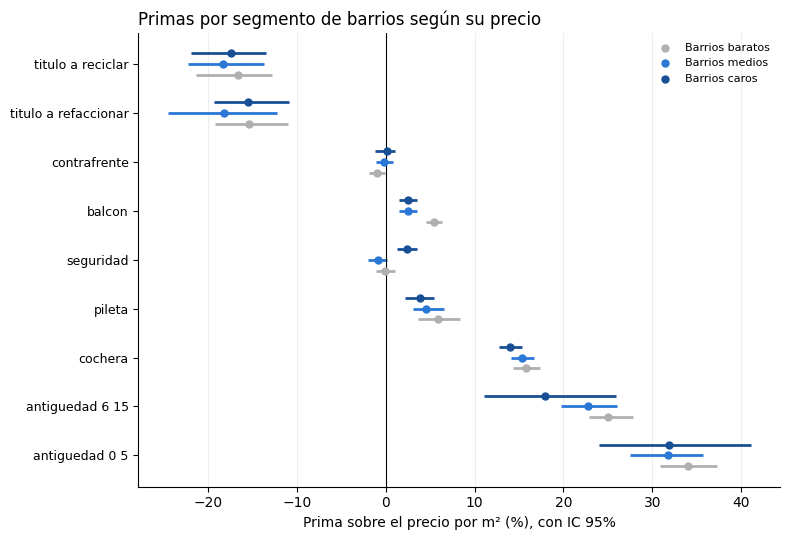

In [21]:
fig, ax = plt.subplots(figsize=(8, 5.5))
colores_seg = {"baratos": GRIS, "medios": AZUL, "caros": AZUL_OSCURO}
desplazamiento = {"baratos": -0.22, "medios": 0, "caros": 0.22}
for seg, tabla in por_segmento.items():
    ys = np.arange(len(clave)) + desplazamiento[seg]
    ax.hlines(ys, tabla["ic_inf_%"], tabla["ic_sup_%"], color=colores_seg[seg], lw=2)
    ax.scatter(tabla["prima_%"], ys, color=colores_seg[seg], s=25, zorder=3, label=f"Barrios {seg}")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(clave)), [c.replace("_", " ") for c in clave], fontsize=9)
ax.set_xlabel("Prima sobre el precio por m² (%), con IC 95%")
ax.set_title("Primas por segmento de barrios según su precio", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper right")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.tight_layout()
plt.show()

> **Interpretación:** _(a completar)_

## 8. Conclusiones y decisiones para la etapa 6

_(a completar con las decisiones que tomemos a partir de las secciones 2 a 7: modelo oficial, uso de las sub-zonas
inestables, intervalo de predicción en el ranking y en el dashboard, y qué se le dice al analista sobre la
incertidumbre de cada brecha.)_

## 9. Qué mira el gradient boosting: valores SHAP

**Pregunta:** el gradient boosting es el modelo con menor error (sección 4), pero no da primas. ¿Qué variables usa
para armar el precio esperado, se parecen a las que usa el lineal, y por qué los dos modelos marcan avisos distintos?

**Qué resuelve.** El valor SHAP reparte la predicción de un aviso entre sus variables: log del precio esperado =
referencia + suma de las contribuciones de cada variable. La referencia es la predicción media sobre un conjunto de
avisos de fondo. Así se puede abrir el modelo aviso por aviso y, promediando, para todo el conjunto.

**Cómo se calcula acá.**
- Cada aviso se explica con el modelo de la vuelta que no lo vio, igual que su precio esperado (sin fuga).
- El explicador exacto para árboles de shap (TreeExplainer) no reproduce bien los cortes por categoría del barrio:
  en una prueba con datos simulados, la suma de los valores no daba la predicción. Por eso se usa el explicador por
  permutación de shap, que solo necesita la función de predicción. Es más lento, así que se calcula sobre los avisos
  marcados por alguno de los dos modelos, con un fondo de 50 avisos al azar del entrenamiento de cada vuelta. El
  resultado se guarda en `data/interim/shap_gbm.tsv` (`validacion.explicar_gbm_guardado`) y se vuelve a calcular
  solo si cambian los avisos, los parámetros o las predicciones del modelo.
- Las columnas que no tienen sentido por separado se explican juntas, como una sola variable: cada dato con su
  marca de "sin dato", los tramos de antigüedad, las categorías del estado según el título y la ubicación (latitud,
  longitud, barrio y mediana de la zona).

**Supuestos.** Para "apagar" una variable se la reemplaza por el valor de un aviso del fondo sin cambiar las demás,
como si fueran independientes. Con variables correlacionadas eso arma combinaciones poco realistas (por ejemplo,
30 m² con 5 ambientes); agrupar las más ligadas lo reduce, no lo elimina.

**Cómo se valida.** La referencia más la suma de las contribuciones tiene que dar la predicción (9.1), y los valores
no tienen que depender mucho del fondo y de la cantidad de evaluaciones (9.2) ni de la vuelta (9.4).

**Qué agrega frente a una alternativa más simple.** La importancia por permutación dice cuánto empeora el error al
desordenar una variable, pero solo para el conjunto. SHAP también explica cada aviso, que es lo que necesita la
ficha del analista.

**Límites.** Explica al modelo, no al mercado: una contribución grande dice que el modelo usa esa variable, no que la
variable cause el precio. Con variables correlacionadas (ubicación y expensas, superficie y ambientes) el reparto del
crédito entre ellas es en parte arbitrario; por eso la lectura principal es por bloques (9.3). Los avisos explicados
son los marcados, no una muestra de todos: la importancia describe al modelo sobre esos avisos. Y el SHAP por
permutación es aproximado: usa un fondo de 50 avisos y 300 evaluaciones del modelo por aviso. Frente a una
versión más precisa (fondo de 200 y 1.000 evaluaciones), las tres variables principales coinciden en el 82% de
los avisos y los valores difieren en promedio un 18% (9.2). Alcanza para leer bloques y los factores principales
de un aviso, no para ordenar contribuciones chicas entre sí.

**Qué va al dashboard.** La ficha muestra el precio esperado del modelo oficial (`analisis.modelo_oficial`), así que
la etapa 6 explica ese modelo (`data/processed/explicacion_avisos.tsv`): con sus contribuciones exactas si es el
lineal ampliado, o con este mismo SHAP si es el gradient boosting. Esta sección analiza el gradient boosting, sea o no
el oficial.

### 9.1 Cálculo y chequeo de la suma

In [22]:
import time

# Mismas vueltas y mismos modelos que en la sección 4, ahora guardando el ajuste de cada vuelta
pred_shap, _, ajustes = validacion.comparar_modelos(df, y, PARAMS["k_folds"], PARAMS["semilla"], PARAMS["minimo_grupo"],
                                                    PARAMS["iqr_k"], modelos=["lineal_ampliado", "gbm"],
                                                    barrios_excluidos=inestables, devolver_modelos=True)
assert np.allclose(pred_shap[["lineal_ampliado", "gbm"]], pred[["lineal_ampliado", "gbm"]])
explicados = marcas["lineal_ampliado"] | marcas["gbm"]

# El SHAP tarda varios minutos: se guarda en data/interim/shap_gbm.tsv y se lee de ahí si corresponde a estos
# avisos, a estos parámetros y a estas predicciones del gradient boosting; si no, se calcula y se guarda
inicio = time.time()
shap_gbm, origen = validacion.explicar_gbm_guardado(ajustes, explicados, CFG["rutas"]["shap_gbm"], df["id_aviso"],
                                                    pred["gbm"], fondo="ciudad", semilla=PARAMS["semilla"])
minutos = (time.time() - inicio) / 60
print(f"SHAP {origen} ({CFG['rutas']['shap_gbm']}), en {minutos:.1f} minutos")
contrib_lineal = validacion.explicar_lineal(ajustes, explicados)
variables = [c for c in shap_gbm.columns if c not in ("base", "vuelta")]
error_suma = (shap_gbm[variables + ["base"]].sum(axis=1) - pred.loc[explicados, "gbm"]).abs().max()
print(f"Avisos explicados (marcados por alguno de los dos modelos): {explicados.sum():,}")
print(f"Variables: {len(variables)} | error máximo de referencia + suma − predicción: {error_suma:.1e} (en log)")

/Users/gonzalobuhler/Documents/Facultad (ITBA)/2026 - 2C/Descriptiva/tp1-fondo-inmobiliario/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP calculado (data/interim/shap_gbm.tsv), en 6.4 minutos


Avisos explicados (marcados por alguno de los dos modelos): 2,144
Variables: 25 | error máximo de referencia + suma − predicción: 1.2e-14 (en log)


### 9.2 ¿Cuánto dependen los valores del fondo?

El explicador por permutación hace dos aproximaciones: usa un fondo de 50 avisos (no todos) y una cantidad limitada
de órdenes de las variables (300 evaluaciones del modelo por aviso). Se recalculan 40 avisos con un fondo de 200,
1.000 evaluaciones y otra semilla, y se compara.

In [23]:
muestra_shap = explicados & (explicados.cumsum() <= 40)
precisa = validacion.explicar_gbm(ajustes, muestra_shap, fondo="ciudad", n_fondo=200, max_evals=1000, semilla=1)[variables]
rapida = shap_gbm.loc[precisa.index, variables]
dif_relativa = (rapida - precisa).abs().mean().mean() / precisa.abs().mean().mean()
mismas_tres = np.mean([set(rapida.loc[i].abs().nlargest(3).index) == set(precisa.loc[i].abs().nlargest(3).index)
                       for i in precisa.index])
print(f"Diferencia media relativa: {100 * dif_relativa:.0f}% | mismas tres variables principales: "
      f"{100 * mismas_tres:.0f}% de los avisos")

Diferencia media relativa: 18% | mismas tres variables principales: 82% de los avisos


### 9.3 Importancia por bloques, comparada con el lineal

Para cada aviso se suman las contribuciones de las variables de un mismo bloque (la suma de valores SHAP también es
un valor SHAP, el del bloque) y se promedia su valor absoluto. Para el lineal ampliado se usan sus contribuciones
exactas (`validacion.explicar_lineal`: coeficiente × diferencia con la media de la zona).

Dos advertencias:
- **La comparación es aproximada: no miden exactamente lo mismo.** El SHAP del gradient boosting compara contra
  avisos de toda la ciudad y el lineal contra la media de la zona del aviso (por eso en el lineal la ubicación queda
  en la referencia y no aparece como bloque). Tampoco es lo mismo que las primas de la sección 6: una prima dice
  cuánto cambia el precio por una unidad de la variable; la importancia dice cuánto movió el precio, en promedio, en
  estos avisos, y depende también de cuánto varía la variable entre ellos.
- **Los % no se suman.** Las contribuciones están en log y cada una se pasa a % con exp(φ) − 1. Esos % no suman el
  precio esperado: se multiplican (referencia × (1 + efecto₁) × (1 + efecto₂) × ...). Para efectos chicos la
  diferencia es mínima; para los grandes, no.

In [24]:
bloque_de = {"log_m2": "Tamaño", "ambientes": "Tamaño", "banos": "Tamaño", "antiguedad": "Antigüedad",
             "piso": "Piso y disposición", "contrafrente": "Piso y disposición",
             "estado_titulo": "Estado y tipología (título)", "titulo_con_inquilino": "Estado y tipología (título)",
             "titulo_casa": "Estado y tipología (título)", "titulo_tipo_casa": "Estado y tipología (título)",
             "expensas": "Expensas", "apto_credito": "Apto crédito", "ubicacion": "Ubicación"}
bloque_de.update({v: "Amenities y cochera" for v in ["cochera"] + modelo.AMENITIES_Y_EXTRAS})
assert set(variables) <= set(bloque_de), set(variables) - set(bloque_de)


def importancia_por_bloque(contrib):
    """Promedio del valor absoluto de la contribución de cada bloque (en log)."""
    vars_ = [c for c in contrib.columns if c not in ("base", "vuelta")]
    return contrib[vars_].T.groupby(bloque_de).sum().T.abs().mean()


importancia = pd.DataFrame({"gbm": importancia_por_bloque(shap_gbm),
                            "lineal": importancia_por_bloque(contrib_lineal)})
tabla_importancia = pd.DataFrame({
    "gbm_efecto_tipico_%": 100 * (np.exp(importancia["gbm"]) - 1),
    "gbm_parte_del_total_%": 100 * importancia["gbm"] / importancia["gbm"].sum(),
    "lineal_efecto_tipico_%": 100 * (np.exp(importancia["lineal"]) - 1),
    "lineal_parte_del_total_%": 100 * importancia["lineal"] / importancia["lineal"].sum(),
}).sort_values("gbm_efecto_tipico_%", ascending=False).round(1)
tabla_importancia

,gbm_efecto_tipico_%,gbm_parte_del_total_%,lineal_efecto_tipico_%,lineal_parte_del_total_%
Ubicación,27.6,47.2,NaN,NaN
Amenities y cochera,9.4,17.5,7.7,30.1
Antigüedad,7.5,14.1,8.3,32.3
Tamaño,6.3,11.8,4.8,18.9
Expensas,2.3,4.5,1.8,7.1
Piso y disposición,1.5,2.8,1.5,6.0
Estado y tipología (título),0.6,1.2,0.7,2.9
Apto crédito,0.5,1.0,0.7,2.9


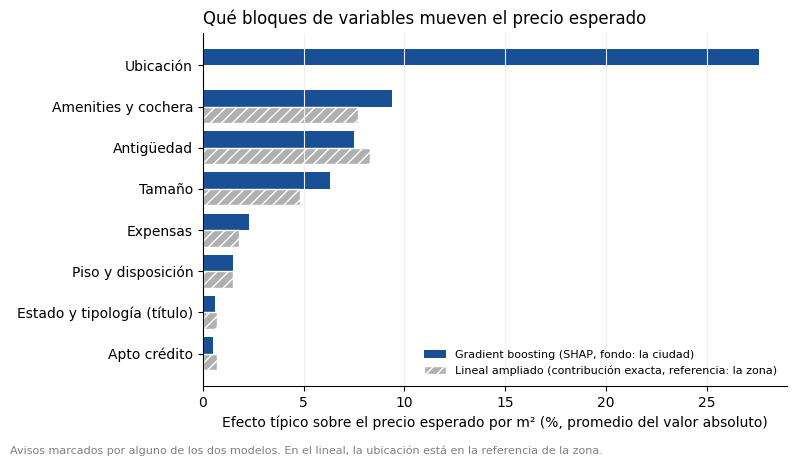

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))
orden_bloques = tabla_importancia.index[::-1]
pos = np.arange(len(orden_bloques))
ax.barh(pos + 0.2, tabla_importancia.loc[orden_bloques, "gbm_efecto_tipico_%"], height=0.4, color=AZUL_OSCURO,
        label="Gradient boosting (SHAP, fondo: la ciudad)")
ax.barh(pos - 0.2, tabla_importancia.loc[orden_bloques, "lineal_efecto_tipico_%"].fillna(0), height=0.4, color=GRIS,
        hatch="///", edgecolor="white", label="Lineal ampliado (contribución exacta, referencia: la zona)")
ax.set_yticks(pos, orden_bloques)
ax.set_xlabel("Efecto típico sobre el precio esperado por m² (%, promedio del valor absoluto)")
ax.set_title("Qué bloques de variables mueven el precio esperado", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.02, "Avisos marcados por alguno de los dos modelos. En el lineal, la ubicación está en la "
            "referencia de la zona.", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

> **Interpretación:** _(a completar)_

### 9.4 ¿Cambia la importancia según la vuelta?

Cada vuelta tiene su propio modelo, entrenado con el 80% de los avisos, y explica a avisos distintos. Si el orden de
los bloques cambiara mucho entre vueltas, la lectura de 9.3 sería frágil. Se mide con la correlación de Spearman
(1 = mismo orden) entre cada par de vueltas.

In [26]:
por_vuelta = pd.DataFrame({p: importancia_por_bloque(g) for p, g in shap_gbm.groupby("vuelta")})
rho = por_vuelta.corr(method="spearman").values[np.triu_indices(por_vuelta.shape[1], 1)]
print(f"Spearman del orden de los bloques entre vueltas: mínimo {rho.min():.2f}, mediana {np.median(rho):.2f}")
(100 * (np.exp(por_vuelta) - 1)).round(1).add_prefix("vuelta_").loc[tabla_importancia.index]

Spearman del orden de los bloques entre vueltas: mínimo 0.98, mediana 1.00


,vuelta_0,vuelta_1,vuelta_2,vuelta_3,vuelta_4
Ubicación,27.4,27.9,27.7,27.1,28.0
Amenities y cochera,9.3,8.7,8.9,10.4,9.8
Antigüedad,7.5,7.3,7.5,7.5,7.8
Tamaño,6.2,5.9,6.1,6.2,6.9
Expensas,2.0,2.3,2.8,2.5,2.3
Piso y disposición,1.6,1.5,1.5,1.2,1.6
Estado y tipología (título),0.7,0.8,0.3,0.6,0.7
Apto crédito,0.4,0.4,0.5,0.5,0.6


### 9.5 Cómo cambia la contribución con la superficie, el piso y la antigüedad

Cada punto es un aviso; en el eje vertical, cuánto aporta esa variable a su precio esperado. El lineal impone una
forma (una recta en el logaritmo de la superficie, una recta en el piso, un escalón por tramo de antigüedad); el
gradient boosting la aprende de los datos. Solo la forma es comparable: el nivel depende de la referencia (la ciudad
para el gradient boosting, la zona para el lineal).

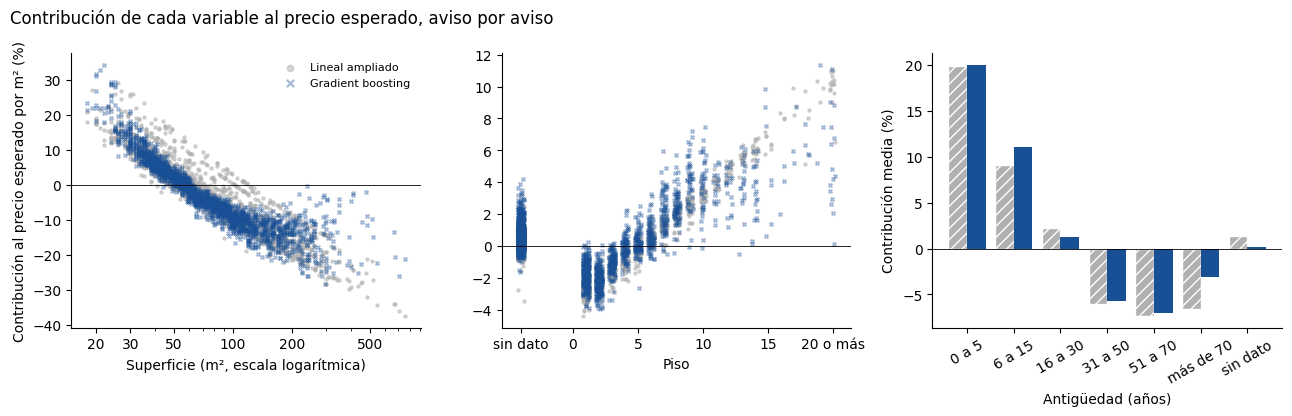

In [27]:
def a_pct(c):
    return 100 * (np.exp(c) - 1)


fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
idx = shap_gbm.index

ax = axes[0]
m2 = df.loc[idx, "m2_final"]
ax.scatter(m2, a_pct(contrib_lineal["log_m2"]), s=5, color=GRIS, alpha=0.5, marker="o", label="Lineal ampliado")
ax.scatter(m2, a_pct(shap_gbm["log_m2"]), s=7, color=AZUL_OSCURO, alpha=0.4, marker="x", label="Gradient boosting")
ax.set_xscale("log")
ax.set_xticks([20, 30, 50, 100, 200, 500], ["20", "30", "50", "100", "200", "500"])
ax.set_xlabel("Superficie (m², escala logarítmica)")
ax.set_ylabel("Contribución al precio esperado por m² (%)")
ax.legend(frameon=False, fontsize=8, markerscale=2)

ax = axes[1]
piso = df.loc[idx, "numero_de_piso_de_la_unidad"].clip(upper=20).fillna(-4)
x_piso = piso + np.random.default_rng(0).uniform(-0.25, 0.25, len(idx))
ax.scatter(x_piso, a_pct(contrib_lineal["piso"]), s=5, color=GRIS, alpha=0.5, marker="o")
ax.scatter(x_piso, a_pct(shap_gbm["piso"]), s=7, color=AZUL_OSCURO, alpha=0.4, marker="x")
ax.set_xticks([-4, 0, 5, 10, 15, 20], ["sin dato", "0", "5", "10", "15", "20 o más"])
ax.set_xlabel("Piso")

ax = axes[2]
tramos = pd.cut(df.loc[idx, "antiguedad"], [-1, 5, 15, 30, 50, 70, np.inf],
                labels=["0 a 5", "6 a 15", "16 a 30", "31 a 50", "51 a 70", "más de 70"])
tramos = tramos.cat.add_categories("sin dato").fillna("sin dato")
medias = pd.DataFrame({"lineal": a_pct(contrib_lineal["antiguedad"]).groupby(tramos, observed=False).mean(),
                       "gbm": a_pct(shap_gbm["antiguedad"]).groupby(tramos, observed=False).mean()})
pos = np.arange(len(medias))
ax.bar(pos - 0.2, medias["lineal"], width=0.4, color=GRIS, hatch="///", edgecolor="white")
ax.bar(pos + 0.2, medias["gbm"], width=0.4, color=AZUL_OSCURO)
ax.set_xticks(pos, medias.index, rotation=30)
ax.set_xlabel("Antigüedad (años)")
ax.set_ylabel("Contribución media (%)")

for ax in axes:
    ax.axhline(0, color="black", lw=0.6)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
fig.suptitle("Contribución de cada variable al precio esperado, aviso por aviso", x=0.01, ha="left")
plt.tight_layout()
plt.show()

> **Interpretación:** _(a completar)_

### 9.6 Por qué los dos modelos difieren en un aviso

Tres avisos: uno que marcan los dos modelos, uno que marca solo el lineal ampliado y uno que marca solo el gradient
boosting. Para que las dos explicaciones sean comparables, acá el gradient boosting se explica contra los avisos de
entrenamiento de la misma zona (como el lineal y como la ficha del dashboard), con un fondo de hasta 200 avisos. Así
la referencia de los dos modelos es el precio típico de la zona, y las barras muestran qué hace que el aviso se
aparte de ella según cada modelo.

Criterio de elección (reproducible): entre los que marcan los dos, el aviso con la brecha más cercana a la mediana
del grupo; entre los que marca uno solo, el aviso cuya diferencia entre los dos precios esperados está en el
percentil 75 del grupo (un caso claro, pero no el más extremo).

In [28]:
brecha_lineal = np.exp(y - pred["lineal_ampliado"]) - 1
brecha_gbm = np.exp(y - pred["gbm"]) - 1
dif_modelos = (pred["lineal_ampliado"] - pred["gbm"]).abs()


def mas_cercano(serie, valor):
    return (serie - valor).abs().idxmin()


solo_lineal = marcas["lineal_ampliado"] & ~marcas["gbm"]
solo_gbm = marcas["gbm"] & ~marcas["lineal_ampliado"]
casos = {
    "Lo marcan los dos": mas_cercano(brecha_lineal[consenso], brecha_lineal[consenso].median()),
    "Solo el lineal ampliado": mas_cercano(dif_modelos[solo_lineal], dif_modelos[solo_lineal].quantile(0.75)),
    "Solo el gradient boosting": mas_cercano(dif_modelos[solo_gbm], dif_modelos[solo_gbm].quantile(0.75)),
}
elegidos = pd.Series(df.index.isin(list(casos.values())), index=df.index)
caso_lineal = validacion.explicar_lineal(ajustes, elegidos)
caso_gbm = validacion.explicar_gbm(ajustes, elegidos, fondo="zona", n_fondo=200, max_evals=1000,
                                   semilla=PARAMS["semilla"])
pd.DataFrame({nombre: {
    "id_aviso": df.at[i, "id_aviso"], "barrio": nombre_barrio(df.at[i, "barrio"]), "zona": oficial.at[i, "zona"],
    "m2": round(df.at[i, "m2_final"]), "ambientes": df.at[i, "ambientes"], "antiguedad": df.at[i, "antiguedad"],
    "titulo": df.at[i, "titulo"][:60],
    "precio_m2_publicado": round(df.at[i, "precio_m2_usd"]),
    "lineal: referencia de la zona": round(np.exp(caso_lineal.at[i, "base"])),
    "lineal: precio esperado": round(np.exp(pred.at[i, "lineal_ampliado"])),
    "lineal: brecha %": round(100 * brecha_lineal[i], 1),
    "gbm: referencia de la zona": round(np.exp(caso_gbm.at[i, "base"])),
    "gbm: precio esperado": round(np.exp(pred.at[i, "gbm"])),
    "gbm: brecha %": round(100 * brecha_gbm[i], 1),
} for nombre, i in casos.items()})

,Lo marcan los dos,Solo el lineal ampliado,Solo el gradient boosting
id_aviso,MLA1947770685,MLA3770427108,MLA2570543840
barrio,San Telmo,Caballito,Recoleta
zona,san-telmo_0,caballito,recoleta_1
m2,52,54,47
ambientes,3.0,2.0,2.0
antiguedad,30.0,2.0,50.0
titulo,Departamento 3 Ambientes Con Balcon En Venta,"Av San Martin 1700, Pont Bleu, Amplio Departam...",Departamento En Venta En Av Del Libertador
precio_m2_publicado,1346,2220,2489
lineal: referencia de la zona,1895,2432,3202
lineal: precio esperado,2006,3418,3263


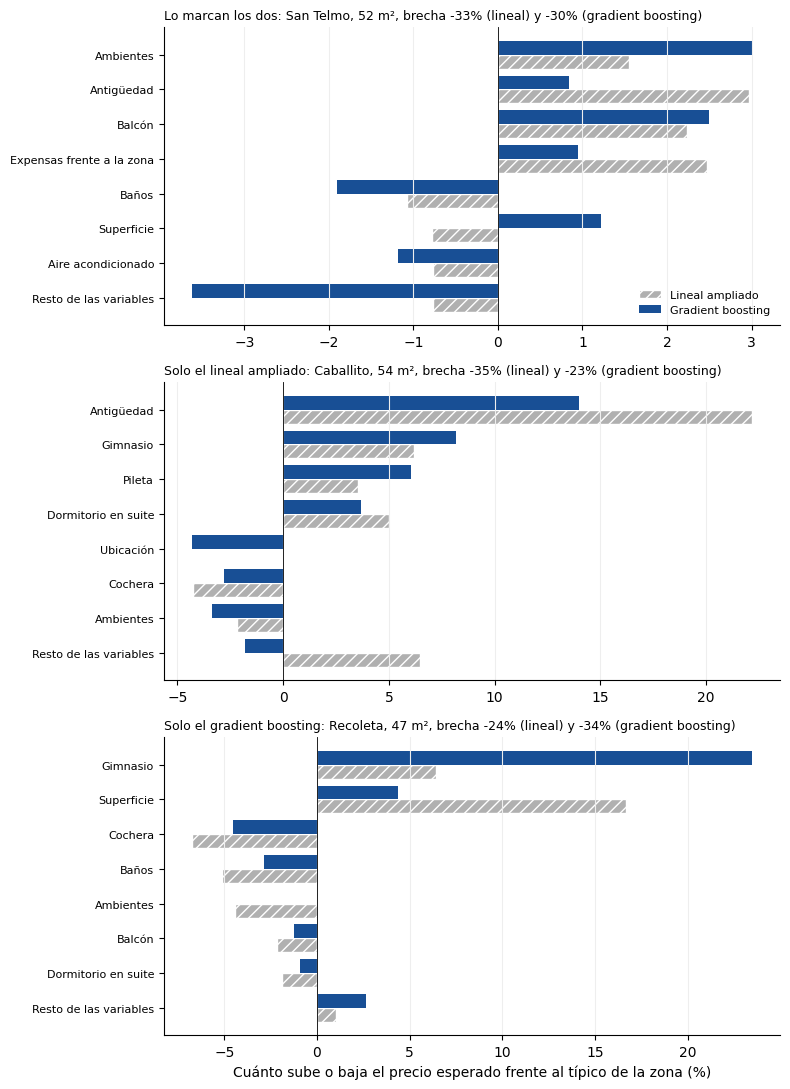

In [29]:
fig, axes = plt.subplots(3, 1, figsize=(8, 11))
for ax, (nombre, i) in zip(axes, casos.items()):
    c = pd.DataFrame({"lineal": caso_lineal.loc[i].drop(["base", "vuelta"]),
                      "gbm": caso_gbm.loc[i].drop(["base", "vuelta"])}).fillna(0)
    top = c.abs().max(axis=1).nlargest(7).index
    c = pd.concat([c.loc[top], c.drop(top).sum().to_frame("resto").T]).iloc[::-1]
    pos = np.arange(len(c))
    ax.barh(pos - 0.2, a_pct(c["lineal"]), height=0.4, color=GRIS, hatch="///", edgecolor="white",
            label="Lineal ampliado")
    ax.barh(pos + 0.2, a_pct(c["gbm"]), height=0.4, color=AZUL_OSCURO, label="Gradient boosting")
    ax.set_yticks(pos, [validacion.ETIQUETAS.get(v, v) if v != "resto" else "Resto de las variables" for v in c.index],
                  fontsize=8)
    ax.axvline(0, color="black", lw=0.6)
    ax.set_title(f"{nombre}: {nombre_barrio(df.at[i, 'barrio'])}, {df.at[i, 'm2_final']:.0f} m², brecha "
                 f"{100 * brecha_lineal[i]:+.0f}% (lineal) y {100 * brecha_gbm[i]:+.0f}% (gradient boosting)",
                 loc="left", fontsize=9)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.grid(axis="x", color="#eeeeee")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
axes[-1].set_xlabel("Cuánto sube o baja el precio esperado frente al típico de la zona (%)")
plt.tight_layout()
plt.show()

> **Interpretación:** _(a completar)_